# Lab 4-2 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab04_2.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [1]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import lab04_2

lab04_2.set_seed()
X, y = lab04_2.load_data('../data/motor_health.csv')
data = lab04_2.prepare_data(X, y)
results = lab04_2.run_experiment(data)

# Re-train the winning configuration to get its per-epoch history.
# Same seed and same data, so this repeats exactly the run that won the search.
best = results['best_config']
lab04_2.set_seed()
best_model = lab04_2.build_model(data['input_dim'], best['hidden_size'])
history = lab04_2.train_model(best_model, data['train_loader'], data['val_loader'], best['lr'])

best, results['val'], results['test']

Matplotlib is building the font cache; this may take a moment.


({'hidden_size': 32, 'lr': 0.1},
 {'loss': 0.335632, 'accuracy': 0.855},
 {'loss': 0.370398, 'accuracy': 0.8475})

## Plot 1 — Learning curves of the selected configuration

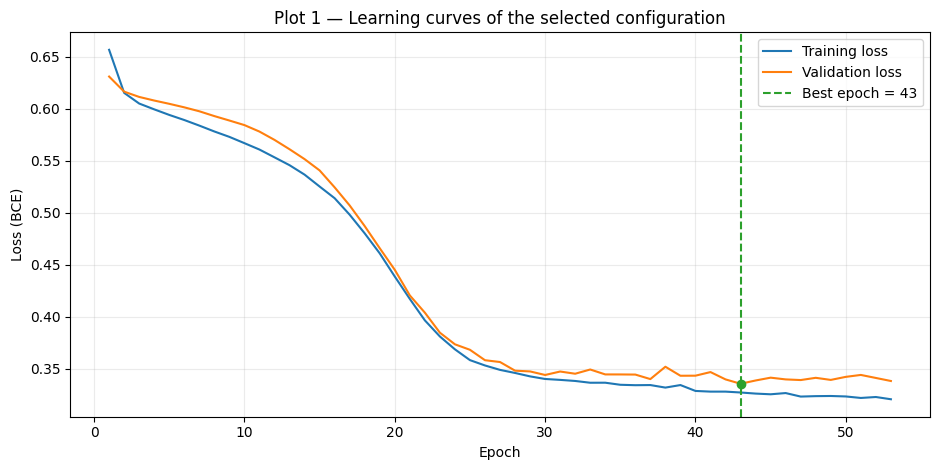

In [2]:
# ============ TODO (Plot 1) ============
# Plot history['train_loss'] and history['val_loss'] against the epoch number (starting at 1).
# Mark history['best_epoch'] with a vertical dashed line. Title + axis labels + legend.

# epoch 번호와 최적 epoch 준비
epochs = np.arange(1, len(history["train_loss"]) + 1)
best_epoch = history["best_epoch"]

# 학습 손실과 검증 손실을 같은 축에 표시
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(epochs, history["train_loss"], label="Training loss", color="tab:blue")
ax.plot(epochs, history["val_loss"], label="Validation loss", color="tab:orange")

# 최적 epoch를 세로 점선과 검증 손실의 점으로 표시
ax.axvline(
    best_epoch, color="tab:green", linestyle="--",
    label=f"Best epoch = {best_epoch}",
)
ax.scatter(
    best_epoch, history["val_loss"][best_epoch - 1],
    color="tab:green", zorder=3,
)

# 노트북의 해당 그림 제목을 그대로 사용
ax.set_title("Plot 1 — Learning curves of the selected configuration")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (BCE)")
ax.legend()
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

# 그림 저장 후 노트북에 표시
fig.tight_layout()
fig.savefig("fig1.png", dpi=300, bbox_inches="tight")
plt.show()
# =======================================


## Plot 2 — The grid

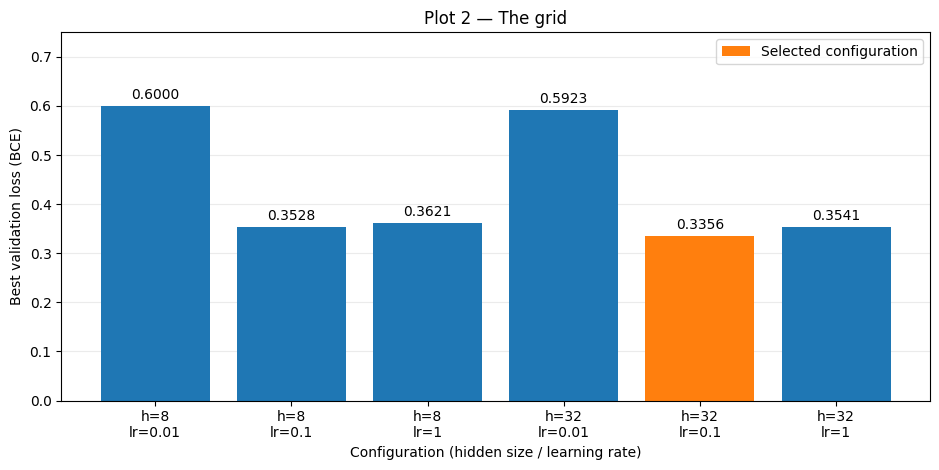

In [3]:
# ============ TODO (Plot 2) ============
# Bar chart of val_loss for every record in results['grid'].
# Label each bar with its configuration, e.g. "h=8\nlr=0.01". Title + axis labels.

# 그리드 순서대로 설정 이름과 최저 검증 손실 준비
grid = results["grid"]
positions = np.arange(len(grid))
labels = [
    f"h={record['hidden_size']}\nlr={record['lr']:g}"
    for record in grid
]
val_losses = [record["val_loss"] for record in grid]

# 최저 검증 손실의 조합을 다른 색으로 표시
best_index = min(range(len(grid)), key=lambda i: grid[i]["val_loss"])
colors = [
    "tab:orange" if i == best_index else "tab:blue"
    for i in range(len(grid))
]

# 여섯 조합의 막대와 손실 값 표시
fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(positions, val_losses, color=colors)
ax.set_xticks(positions, labels)
ax.bar_label(bars, fmt="%.4f", padding=3)
bars[best_index].set_label("Selected configuration")

# 노트북의 해당 그림 제목을 그대로 사용
ax.set_title("Plot 2 — The grid")
ax.set_xlabel("Configuration (hidden size / learning rate)")
ax.set_ylabel("Best validation loss (BCE)")
ax.set_ylim(0, max(val_losses) * 1.25)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# 그림 저장 후 노트북에 표시
fig.tight_layout()
fig.savefig("fig2.png", dpi=300, bbox_inches="tight")
plt.show()
# =======================================


## Plot 3 — Validation against test

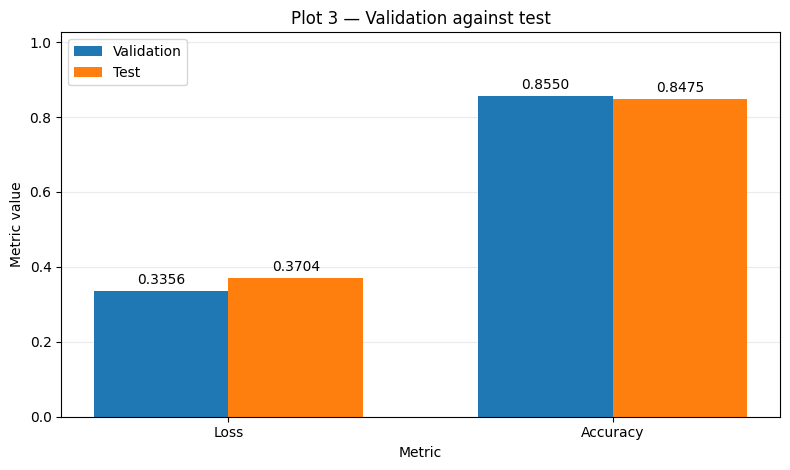

In [4]:
# ============ TODO (Plot 3) ============
# Grouped bar chart comparing results['val'] and results['test'] on loss and on accuracy,
# for the selected configuration only. Title + axis labels + legend.

# 선택 모델의 검증 및 테스트 지표 준비
metric_names = ["Loss", "Accuracy"]
positions = np.arange(len(metric_names))
width = 0.35
val_values = [results["val"]["loss"], results["val"]["accuracy"]]
test_values = [results["test"]["loss"], results["test"]["accuracy"]]

# 같은 지표의 검증 및 테스트 막대를 나란히 배치
fig, ax = plt.subplots(figsize=(8, 4.8))
val_bars = ax.bar(
    positions - width / 2, val_values, width,
    label="Validation", color="tab:blue",
)
test_bars = ax.bar(
    positions + width / 2, test_values, width,
    label="Test", color="tab:orange",
)
ax.set_xticks(positions, metric_names)
ax.bar_label(val_bars, fmt="%.4f", padding=3)
ax.bar_label(test_bars, fmt="%.4f", padding=3)

# 노트북의 해당 그림 제목을 그대로 사용
ax.set_title("Plot 3 — Validation against test")
ax.set_xlabel("Metric")
ax.set_ylabel("Metric value")
ax.set_ylim(0, max(val_values + test_values) * 1.2)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# 그림 저장 후 노트북에 표시
fig.tight_layout()
fig.savefig("fig3.png", dpi=300, bbox_inches="tight")
plt.show()
# =======================================
